# LinkedIn charts

This notebook only makes the six charts for the LinkedIn carousel, in story order. All the exploring, checking and dead ends live in `01_exploration.ipynb`.

Each section loads just the data it needs, so the notebook runs top to bottom with **Restart Kernel and Run All**. Every chart is saved to `outputs/` as a 1080 x 1350 PNG.

## Setup

In [3]:
import os
import warnings
import pandas as pd
import plotly.express as px
import plotly.io as pio
import plotly.graph_objects as go

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")

# Run this once if saving images complains about Chrome:
# import kaleido; kaleido.get_chrome_sync()

### File paths

Every file this notebook uses, in one place. When the new data comes out, download the new files and only change the names here.

In [5]:
vis_path = "../data/processed/vis_d02.parquet"
ons_path = "../data/raw/may2026publicationspreadsheet.xlsx"
mj_path = "../data/raw/migrant-journey-detailed-datasets-2025.xlsx"
occ_path = "../data/raw/occupation-soc2020-visas-datasets-jun-2026.xlsx"
se_path = "../data/raw/settlement-datasets-jun-2026.xlsx"
sfc_csv = "../data/manual/skills_for_care_2026.csv"
fees_path = "../data/manual/Fees_Table_08_October_26.ods"

os.makedirs("../outputs", exist_ok=True)

### Style

Two layers. The template gives every chart the same colours and background. `finish()` is only for the LinkedIn charts: it adds the big headline, subtitle and source line, sets the 1080 x 1350 size, colours each series from `COLORS` and saves the PNG.

`COLORS` is what makes the carousel read as one piece: British is always blue, non EU always aqua, dependants always orange, proposed rules always orange.

In [7]:
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
YELLOW, ORANGE, RED, TURQ = "#FFCF00", "#EE6123", "#FA003F", "#72E1D1"
OLD = "#d6d5ce"   # for background lines, like the older student years

COLORS = {
    "All Nationalities": ORANGE, "British": RED, "EU+": YELLOW, "Non-EU+": TURQ,
    "EU": YELLOW, "Non EU": TURQ,
    "Main Applicant": RED, "Dependant": YELLOW,
    "Current rules": TURQ, "Proposed rules": ORANGE,
    "Current (5 years)": TURQ, "Proposed 10 year rule": ORANGE,
}

pio.templates["immig"] = go.layout.Template(layout=dict(
    font=dict(family="Segoe UI, Arial, sans-serif", color=INK),
    paper_bgcolor=SURFACE, plot_bgcolor=SURFACE,
    colorway=[RED, YELLOW, TURQ, ORANGE],
    xaxis=dict(showgrid=False, zeroline=False, linecolor=AXIS, tickfont=dict(color=MUTED), title_font=dict(color=INK2)),
    yaxis=dict(gridcolor=GRID, zerolinecolor=AXIS, tickfont=dict(color=MUTED), title_font=dict(color=INK2)),
    legend=dict(title_text=""),
    bargap=0.25,
))
pio.templates.default = "plotly_white+immig"


def finish(fig, title, subtitle, source, name, height=1350):
    W, H, T, B = 1080, height, 180, 170          # image size and top/bottom margins in pixels
    plot_h = H - T - B                          # height of the plot area itself

    fig.update_layout(
        width=W, height=H,
        font=dict(size=22),
        margin=dict(l=90, r=40, t=T, b=B),
        legend=dict(orientation="h", x=0, y=1.0, yanchor="bottom", title_text=""),
        title=dict(text=f"<b>{title}</b><br><span style='font-size:22px;color:{INK2}'>{subtitle}</span>",
                   x=0.02, xanchor="left", y=0.97, yref="container", yanchor="top",
                   font=dict(size=32)),
    )
    for tr in fig.data:
        if tr.name in COLORS:
            if tr.type == "bar":
                tr.marker.color = COLORS[tr.name]
            else:
                tr.line.color = COLORS[tr.name]
    fig.update_traces(marker_line_color=SURFACE, marker_line_width=2, selector=dict(type="bar"))
    fig.update_traces(line_width=3, marker_size=9, selector=dict(type="scatter"))

    # Source line: 15 px above the bottom edge of the image, converted to paper units
    fig.add_annotation(text=source, xref="paper", yref="paper", x=0, y=-(B - 15) / plot_h,
                       xanchor="left", yanchor="bottom", showarrow=False, align="left",
                       font=dict(size=16, color=MUTED))
    fig.write_image(f"../outputs/{name}.png", scale=2)
    return fig

## 1. Net migration by nationality

**Finding:** the total is back to roughly pre Covid levels, but the mix has completely changed: mostly non EU now, EU slightly negative, and more British people leave than arrive every year.

Data: ONS long term international migration, table 1. Periods are rolling 12 month totals, so they're plotted as a line and never added up. Provisional estimates are shaded.

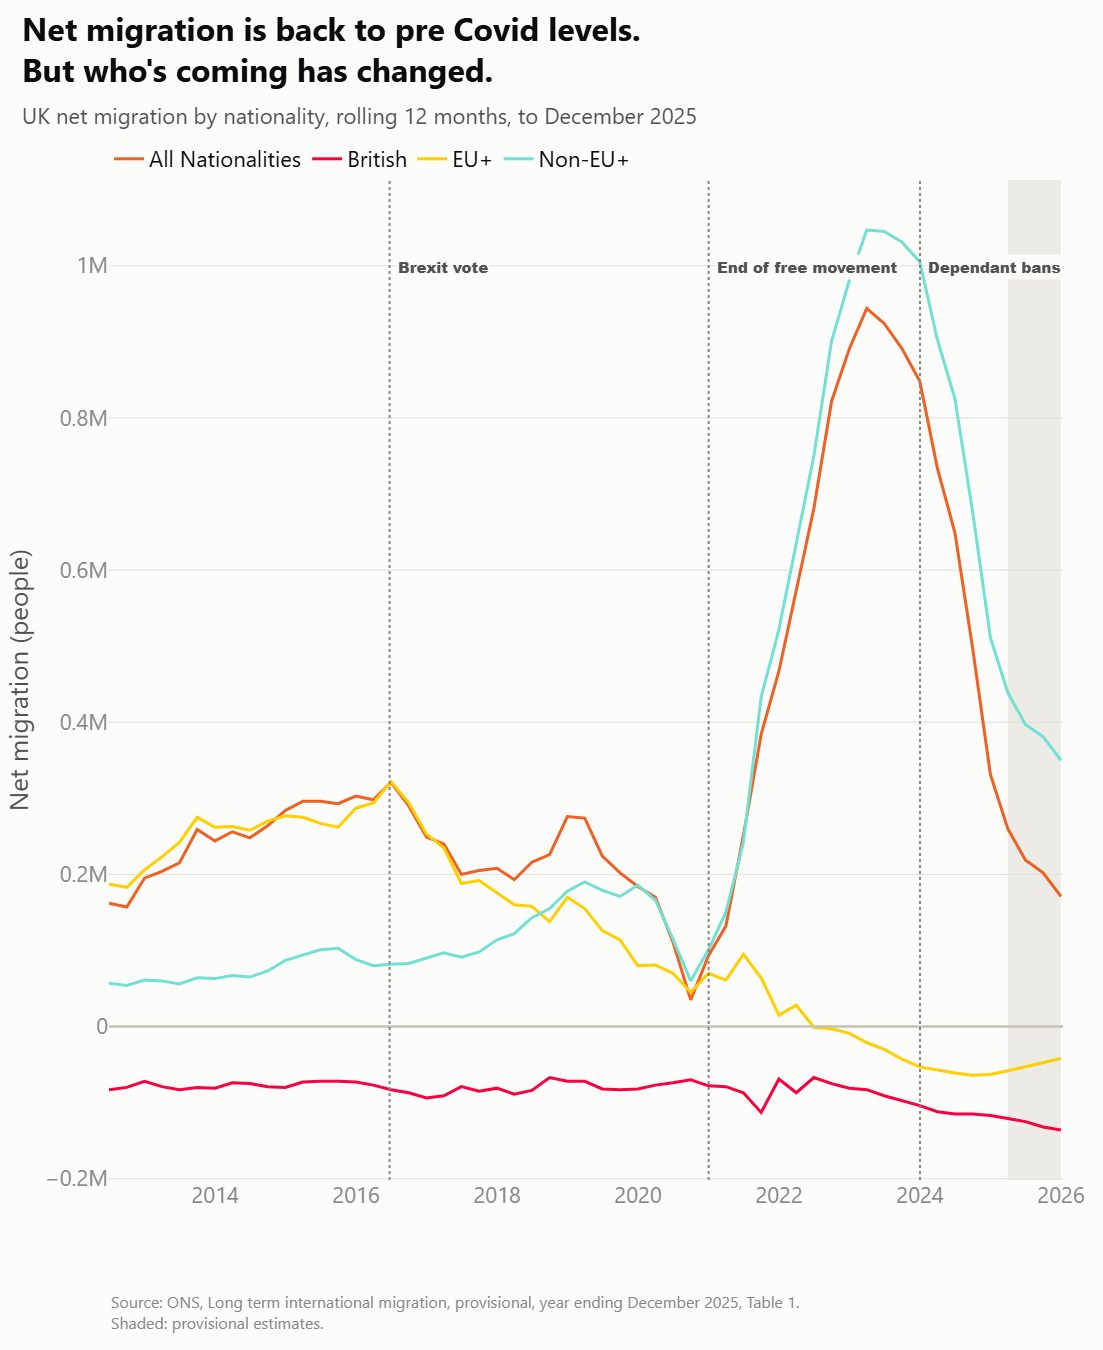

In [37]:
def load_ons_table(path, sheet, skiprows=5):
    df = pd.read_excel(path, sheet_name=sheet, skiprows=skiprows)
    df.columns = (df.columns
                  .str.replace(r"\n?\[.*?\]", "", regex=True)
                  .str.replace("\n", " ")
                  .str.strip())
    df["Provisional"] = df["Period"].str.contains(r"\bP\b")
    period = df["Period"].str.extract(r"^(YE \w{3} \d{2})")[0]
    df["Date"] = pd.to_datetime(period.str[3:], format="%b %y") + pd.offsets.MonthEnd(0)
    return df

t1 = load_ons_table(ons_path, "1")

net = t1[t1["Flow"] == "Net migration"].melt(
    id_vars=["Date"], value_vars=["All Nationalities", "British", "EU+", "Non-EU+"],
    var_name="Nationality", value_name="People")

fig = px.line(net, x="Date", y="People", color="Nationality")
fig.add_hline(y=0, line_color=AXIS)

first_p = t1.loc[t1["Provisional"], "Date"].min()
fig.add_vrect(x0=first_p, x1=t1["Date"].max(), fillcolor=GRID, opacity=0.6, line_width=0,layer="below")

events = {"2016-06-23": "Brexit vote", "2021-01-01": "End of free movement", "2024-01-01": "Dependant bans"}
for date, label in events.items():
    fig.add_vline(x=date, line_dash="dot", line_color=MUTED)
    fig.add_annotation(x=date, y=0.90, yref="paper", text=label,bgcolor=SURFACE, showarrow=False,
                       xanchor="left", yanchor="bottom", xshift=6, font=dict(family='Arial Black',size=15, color=INK2))

fig.update_layout(xaxis_title="", yaxis_title="Net migration (people)")

finish(fig,
       title="Net migration is back to pre Covid levels.<br>But who's coming has changed.",
       subtitle="UK net migration by nationality, rolling 12 months, to December 2025",
       source="Source: ONS, Long term international migration, provisional, year ending December 2025, Table 1.<br>"
              "Shaded: provisional estimates.",
       name="01_net_migration").show()

## 2. Dependants

**Finding (the honest one):** families were a big part of the 2022 and 2023 peak, especially for work visas. After the 2024 bans, study dependants fell about 86% and work dependants about 67%.

Data: Home Office entry clearance visas (Vis_D02), granted visas only, visitors excluded.

In [11]:
vis = pd.read_parquet(vis_path)
vg = vis[(vis["Case outcome"] == "Issued") & (vis["Visa type group"] != "Visitor")]

deps = (vg[vg["Year"].between(2021, 2025) & vg["Visa type group"].isin(["Study", "Work"])
           & vg["Applicant type"].isin(["Main Applicant", "Dependant"])]
        .groupby(["Year", "Visa type group", "Applicant type"])["Decisions"].sum()
        .reset_index())

dep_only = deps[deps["Applicant type"] == "Dependant"].sort_values("Year")

fig = px.line(dep_only, x="Year", y="Decisions", color="Visa type group", markers=True,
              color_discrete_map={"Work": ORANGE, "Study": TURQ})
fig.update_layout(showlegend=False)

for group, d in dep_only.groupby("Visa type group"):
    peak = d.loc[d["Year"] == 2023, "Decisions"].iloc[0]
    last = d["Decisions"].iloc[-1]
    drop = (1 - last / peak) * 100
    # Name and drop at the end of each line
    fig.add_annotation(x=2025, y=last, text=f"<b>{group}</b><br>−{drop:.0f}% since 2023",
                       xanchor="left", xshift=14, showarrow=False, align="left",
                       font=dict(size=20, color=INK))
    # Peak value
    fig.add_annotation(x=2023, y=peak, text=f"{peak/1000:.0f}k", yanchor="bottom", yshift=12,
                       showarrow=False, font=dict(size=18, color=INK2))

fig.add_vline(x=2023.5, line_dash="dot", line_color=MUTED)
fig.add_annotation(x=2023.5, y=0.98, yref="paper", text="Dependant<br>bans", showarrow=False,
                   xanchor="left", yanchor="top", xshift=6, align="left", font=dict(size=16, color=INK2))

fig.update_xaxes(range=[2020.7, 2026.4], tickvals=[2021, 2022, 2023, 2024, 2025], title="")
fig.update_yaxes(rangemode="tozero", title="Family members granted visas")

finish(fig,
       title="Families were a big part of the 2023 peak.<br>Then the rules changed.",
       subtitle="Family members (dependants) granted study and work visas, 2021 to 2025",
       source="Source: Home Office, Entry clearance visa outcomes (Vis_D02), year ending June 2026.<br>"
              "Bans: dependants of most students (January 2024) and care workers (March 2024).",
       name="02_dependants").show()

## 3. Students over time

**Finding:** for years, about 9 in 10 students left. Since 2020, students stay roughly twice as long, mostly working. This lines up with the Graduate visa (July 2021).

Data: Home Office Migrant journey 2025 (MJ_D01). "Still here" means valid leave or ILR. Earlier years in grey, the three most recent with enough years of data in colour.

In [13]:
mj = pd.read_excel(mj_path, sheet_name="Data - MJ_D01 ", skiprows=1)
mj = mj[mj["Initial leave type group"].notna() & (mj["Initial leave type group"] != "End of table")].copy()
mj["Year of initial leave"] = mj["Year of initial leave"].astype(int)
mj["Years since start"] = mj["Year"].astype(int) - mj["Year of initial leave"]

study = mj[mj["Initial leave type"] == "Sponsored study"]
status = (study.groupby(["Year of initial leave", "Years since start",
                         "Immigration Status at end of year"])["Journeys"]
          .sum().unstack(fill_value=0))
total = status.sum(axis=1)
status["Still here %"] = (status["Valid leave to remain"] + status["Indefinite leave to remain"]) / total * 100

after3 = status.reset_index()
after3 = after3[(after3["Years since start"] == 3)
                & after3["Year of initial leave"].between(2012, 2022)].copy()
after3["Group"] = after3["Year of initial leave"].apply(
    lambda y: "Arrived 2020 or later" if y >= 2020 else "Arrived 2012 to 2019")

fig = px.bar(after3, x="Year of initial leave", y="Still here %", color="Group",
             color_discrete_map={"Arrived 2012 to 2019": OLD, "Arrived 2020 or later": TURQ})
fig.update_traces(texttemplate="%{y:.0f}%", textposition="outside")

fig.add_vline(x=2019.5, line_dash="dot", line_color=MUTED)
fig.add_annotation(x=2019.5, y=0.98, yref="paper", text="Graduate visa<br>opens July 2021",
                   showarrow=False, xanchor="right", yanchor="top", xshift=-8, align="right",
                   font=dict(size=16, color=INK2))

fig.update_xaxes(dtick=1, title="Year students arrived")
fig.update_yaxes(range=[0, 100], ticksuffix="%", title="Still in the UK 3 years later")
finish(fig,
       title="Students used to mostly leave.<br>Since 2020, far more stay on.",
       subtitle="Of each year's international students, the share still in the UK (on any visa) 3 years after arriving",
       source="Source: Home Office, Migrant journey 2025 (MJ_D01), sponsored study, main applicants and dependants.<br>"
              "Latest data covers up to 2025, so 2022 is the last group followed for 3 years.",
       name="03_students").show()

## 4. Care workers

**Finding:** between 2020/21 and 2025/26, British workers in adult social care fell by about 130k while non EU workers rose by about 310k. Overseas workers filled the gap British workers left.

Data: Skills for Care, Size and Structure 2026, Table 2 (typed in from the report with page references, see `data/manual/`).

In [15]:
sfc = pd.read_csv(sfc_csv)
w = sfc.pivot(index="year_start", columns="measure", values="value")
change = (w.loc[2025] - w.loc[2020])[["filled_posts_british", "filled_posts_eu", "filled_posts_non_eu"]]
change.index = ["British", "EU", "Non EU"]

cdf = change.reset_index()
cdf.columns = ["Nationality", "Change"]

fig = px.bar(cdf, x="Nationality", y="Change", color="Nationality", text_auto="+.s")
fig.update_layout(showlegend=False, xaxis_title="", yaxis_title="Change in filled posts")
fig.update_traces(textposition="outside")

finish(fig,
       title="British care workers left.<br>Workers from abroad filled the gap.",
       subtitle="Change in adult social care jobs filled, England, 2020/21 to 2025/26",
       source="Source: Skills for Care, The size and structure of the adult social care sector<br>"
              "and workforce in England 2026, Table 2.",
       name="04_care_workforce").show()

## 5. The cost of settling

**Finding:** at today's fees, one person spends about £16,900 in Home Office fees getting from a student visa to citizenship, and a family of four on a Skilled Worker visa about £43,800. A 10 year route would push those to about £24,000 and £69,500.

Data: Home Office fee table (8 October 2026), read straight from the official file. The health surcharge isn't in that table, so it's the only typed in number (gov.uk, unchanged since 6 February 2024).

In [17]:
fees_tbl = pd.read_excel(fees_path, engine="odf", sheet_name="Fees_Table_08_Oct", skiprows=3)
fees_tbl.columns = ["Category", "Previous fee", "Fee", "Change", "Pct change"]
is_section = fees_tbl["Fee"].isna()
fees_tbl["Section"] = fees_tbl["Category"].where(is_section).ffill()
fees_tbl = fees_tbl[~is_section].copy()
for col in ["Category", "Section"]:
    fees_tbl[col] = (fees_tbl[col].str.replace(r"\s*\[Footnote.*?\]", "", regex=True)
                     .str.replace(r"\s+", " ", regex=True).str.strip())


def get_fee(section_has, *words):
    mask = fees_tbl["Section"].str.contains(section_has, case=False, na=False)
    for word in words:
        mask &= fees_tbl["Category"].str.contains(word, case=False, na=False, regex=False)
    match = fees_tbl[mask]
    if len(match) != 1:
        raise ValueError(f"Expected 1 match for {words} in '{section_has}', found {len(match)}")
    return match["Fee"].iloc[0]


in_uk_work = "Work - applications made in the UK"
fees = {
    "student_visa": get_fee("Study - applications made outside the UK", "Student - main applicant"),
    "graduate_visa": get_fee(in_uk_work, "Graduate Route"),
    "skilled_worker_up_to_3y_in_uk": get_fee(in_uk_work, "Skilled Worker, where", "three years or less"),
    "skilled_worker_up_to_3y_outside_uk": get_fee("Work - applications made outside the UK",
                                                  "Skilled Worker, where", "three years or less"),
    "ilr": get_fee("Other applications made in the UK", "Indefinite leave to remain"),
    "life_in_uk_test": get_fee("Other applications made in the UK", "Life in the UK test"),
    "naturalisation_adult": get_fee("Nationality", "Naturalisation (British citizenship)"),
    "citizenship_ceremony": get_fee("Nationality", "arrangement of a citizenship ceremony"),
    "child_registration": get_fee("Nationality", "British citizen - child"),
}
# Immigration Health Surcharge, gov.uk: https://www.gov.uk/healthcare-immigration-application/how-much-pay
fees["ihs_standard"] = 1035
fees["ihs_student_child"] = 776
fees

{'student_visa': 558.0,
 'graduate_visa': 937.0,
 'skilled_worker_up_to_3y_in_uk': 943.0,
 'skilled_worker_up_to_3y_outside_uk': 819.0,
 'ilr': 3226.0,
 'life_in_uk_test': 50.0,
 'naturalisation_adult': 1709.0,
 'citizenship_ceremony': 130.0,
 'child_registration': 1000.0,
 'ihs_standard': 1035,
 'ihs_student_child': 776}

In [18]:
def sw_visas(sw_years, first_fee, later_fee, ihs_per_year, people=1):
    """Skilled Worker visas in chunks of up to 3 years: (step, application fees, surcharge)."""
    steps, remaining, n = [], sw_years, 1
    while remaining > 0:
        y = min(3, remaining)
        fee = first_fee if n == 1 else later_fee
        steps.append((f"Skilled Worker visa {n} ({y} years)", fee * people, ihs_per_year * y))
        remaining -= y
        n += 1
    return steps


def journey(sw_years):
    steps = [("Student visa", fees["student_visa"], fees["ihs_student_child"] * 1.5),
             ("Graduate visa", fees["graduate_visa"], fees["ihs_standard"] * 2)]
    steps += sw_visas(sw_years, fees["skilled_worker_up_to_3y_in_uk"],
                      fees["skilled_worker_up_to_3y_in_uk"], fees["ihs_standard"])
    steps.append(("ILR + Life in the UK test", fees["ilr"] + fees["life_in_uk_test"], 0))
    steps.append(("Citizenship", fees["naturalisation_adult"] + fees["citizenship_ceremony"], 0))
    return pd.DataFrame(steps, columns=["Step", "Application fees", "Health surcharge"])


def family_journey(sw_years, adults=2, children=2):
    people = adults + children
    ihs_per_year = adults * fees["ihs_standard"] + children * fees["ihs_student_child"]
    steps = sw_visas(sw_years, fees["skilled_worker_up_to_3y_outside_uk"],
                     fees["skilled_worker_up_to_3y_in_uk"], ihs_per_year, people)
    steps.append(("ILR (whole family)", fees["ilr"] * people + fees["life_in_uk_test"] * adults, 0))
    steps.append(("Citizenship (whole family)",
                  (fees["naturalisation_adult"] + fees["citizenship_ceremony"]) * adults
                  + fees["child_registration"] * children, 0))
    return pd.DataFrame(steps, columns=["Step", "Application fees", "Health surcharge"])


def total(df):
    return (df["Application fees"] + df["Health surcharge"]).sum()


compare = pd.DataFrame([
    {"Who": "One person<br>(student route)", "Rules": "Current (5 years)", "Cost": total(journey(5))},
    {"Who": "One person<br>(student route)", "Rules": "Proposed 10 year rule", "Cost": total(journey(10))},
    {"Who": "Family of four<br>(Skilled Worker)", "Rules": "Current (5 years)", "Cost": total(family_journey(5))},
    {"Who": "Family of four<br>(Skilled Worker)", "Rules": "Proposed 10 year rule", "Cost": total(family_journey(10))},
])
compare

,Who,Rules,Cost
0,One person<br>(student route),Current (5 years),16905.0
1,One person<br>(student route),Proposed 10 year rule,23966.0
2,Family of four<br>(Skilled Worker),Current (5 years),43840.0
3,Family of four<br>(Skilled Worker),Proposed 10 year rule,69494.0


In [19]:
seg_colors = {"Student": TURQ, "Graduate": YELLOW, "Skilled Worker": ORANGE}
citizenship_fee = fees["naturalisation_adult"] + fees["citizenship_ceremony"]
plans = [("WHAT WE PLANNED (CURRENT RULES)", 5, 1.0),
         ("IF THE 10 YEAR RULE APPLIES", 10, 0.42)]

fig = go.Figure()
costs = {}
for label, sw, row in plans:
    start = 0
    segments = [("Student", 1.3, "Student<br>~1 yr"),
                ("Graduate", 2, "Graduate<br>2 yrs"),
                ("Skilled Worker", sw, f"Skilled Worker<br>{sw} yrs")]
    for seg, length, text in segments:
        fig.add_trace(go.Bar(y=[row], x=[length], base=[start], orientation="h", width=0.11,
                             marker_color=seg_colors[seg], showlegend=False))
        fig.add_annotation(x=start + length / 2, y=row - 0.075, text=text, showarrow=False,
                           yanchor="top", font=dict(size=17, color=INK2))
        start += length

    cost = total(journey(sw)) - citizenship_fee
    costs[sw] = cost
    fig.add_annotation(x=0, y=row + 0.2, text=label, showarrow=False, xanchor="left",
                       yanchor="bottom", font=dict(size=18, color=MUTED))
    fig.add_annotation(x=0, y=row + 0.065, showarrow=False, xanchor="left", yanchor="bottom",
                       text=f"<b>{round(start)} years</b><span style='font-size:30px;color:{INK2}'>"
                            f"  to settle, £{cost:,.0f} for the visa holder</span>",
                       font=dict(size=60, color=INK))

extra = costs[10] - costs[5]
fig.add_annotation(x=0, y=0.2, showarrow=False, xanchor="left", yanchor="top",
                   text=f"<b>+5 years and +£{extra:,.0f}</b> in Home Office fees, for the same person",
                   font=dict(size=26, color=INK))

fig.update_layout(barmode="overlay")
fig.update_xaxes(range=[0, 14], visible=False)
fig.update_yaxes(range=[-0.12, 1.32], visible=False)

finish(fig,
       title="We planned to settle after 8 years.<br>The new rules could make it 13.",
       subtitle="Student, then Graduate, then Skilled Worker visa.<br>The proposals would apply to people already here.",
       source="Source: Home Office immigration and nationality fees, 8 October 2026; Immigration Health Surcharge (gov.uk).<br>"
              "Fees the visa holder is responsible for, up to ILR. Some employers choose to cover the visa fee or surcharge.<br>"
              "Employers also pay sponsorship costs (not included). Excludes English tests and legal fees.",
       name="05_cost", height=1000).show()

## 6. The settlement wave

**Finding:** from visas granted 2021 to 2025, about 1.24 million people could become eligible for settlement in 2026 to 2030 under current rules, peaking in 2028 because of the care worker recruitment. Under the proposals (NHS health workers and BN(O) 5 years, Skilled Worker 10, care workers 15), that wave is pushed years later, with care workers furthest back.

This is a cohort projection, not a forecast: arrivals by route x share still here after 5 years (Migrant journey), eligible after each route's wait. It only counts people who got their visa from abroad, and assumes future groups stay at 2020 rates.

In [21]:
occ = pd.read_excel(occ_path, sheet_name="Data_Occ_D02", skiprows=3)
hc_occ = occ[(occ["Visa type subgroup"] == "Health and Care Worker") & occ["Year"].between(2021, 2025)]
care_share = (hc_occ[hc_occ["Occ. minor group"].str.startswith("613")].groupby("Year")["Grants"].sum()
              / hc_occ.groupby("Year")["Grants"].sum())

stay = {"Skilled Worker": 0.83, "Health and Care Worker": 0.915, "BN(O)": 0.98}
wait = {"Skilled Worker": 10, "Health workers": 5, "Care workers": 15, "BN(O)": 5}
routes = {
    "Skilled Worker": vg["Visa type subgroup"] == "Skilled Worker",
    "Health and Care Worker": vg["Visa type subgroup"] == "Health and Care Worker",
    "BN(O)": vg["Visa type"] == "BN(O) route",
}

rows = []
for route, mask in routes.items():
    arrivals = vg[mask & vg["Year"].between(2021, 2025)].groupby("Year")["Decisions"].sum()
    for year, n in arrivals.items():
        still = n * stay[route]
        if route == "Health and Care Worker":
            parts = {"Care workers": still * care_share[year], "Health workers": still * (1 - care_share[year])}
        else:
            parts = {route: still}
        for name, people in parts.items():
            rows.append({"Route": name, "Arrived": year, "Still here": round(people),
                         "Eligible, current rules": year + 5,
                         "Eligible, proposed rules": year + wait[name]})
model = pd.DataFrame(rows)

proj = pd.DataFrame({
    "Current rules": model.groupby("Eligible, current rules")["Still here"].sum(),
    "Proposed rules": model.groupby("Eligible, proposed rules")["Still here"].sum(),
}).fillna(0).reindex(range(2026, 2041), fill_value=0)

se = pd.read_excel(se_path, sheet_name="Data_Se_D02", skiprows=1)
se.columns = se.columns.str.strip()
ilr_2025 = se[(se["Outcome"] == "Grant") & (se["Year"] == 2025)]["Decisions"].sum()

print(proj.sum(), ilr_2025)

Current rules     1243651.0
Proposed rules    1243651.0
dtype: float64 146119


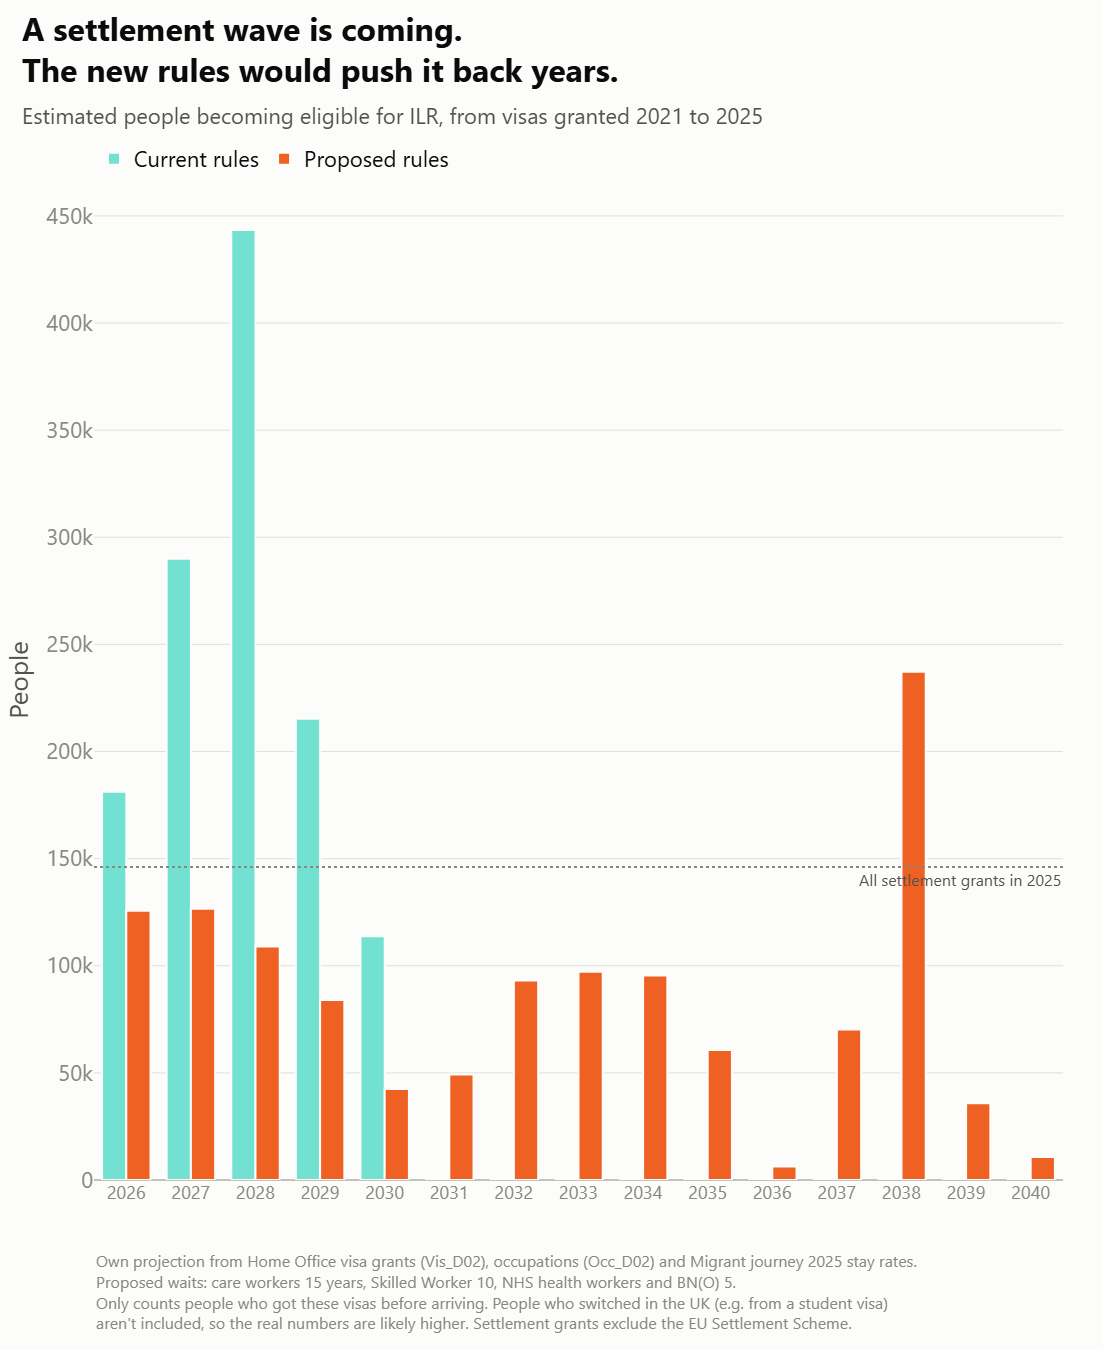

In [35]:
fig = px.bar(proj, barmode="group")
fig.add_hline(y=ilr_2025, line_dash="dot", line_color=MUTED,
              annotation_text="All settlement grants in 2025", annotation_position="bottom right",
              annotation_font=dict(color=INK2, size=16))
fig.update_layout(xaxis_title="", yaxis_title="People")
fig.update_xaxes(dtick=1, tickangle=0, tickfont=dict(size=18))

finish(fig,
       title="A settlement wave is coming.<br>The new rules would push it back years.",
       subtitle="Estimated people becoming eligible for ILR, from visas granted 2021 to 2025",
       source="Own projection from Home Office visa grants (Vis_D02), occupations (Occ_D02) and Migrant journey 2025 stay rates.<br>"
              "Proposed waits: care workers 15 years, Skilled Worker 10, NHS health workers and BN(O) 5.<br>"
              "Only counts people who got these visas before arriving. People who switched in the UK (e.g. from a student visa)<br>"
              "aren't included, so the real numbers are likely higher. Settlement grants exclude the EU Settlement Scheme.",
       name="06_settlement_wave").show()